LIBRARY


In [89]:
import pandas as pd 
import seaborn as sns
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

FUNCTION


In [90]:
def clean(data):
    df = pd.DataFrame(columns=['Year', 'Age', 'Female', 'Male', 'Total'])

    for i in range(len(data)):
        row = data.iloc[i, 0].split()
        df.loc[len(df)] = row
    
    for column in df.columns:
        if df[column].dtype == "object":
            df[column] = df[column].str.replace(r'[+-]', '', regex=True)
    
    for column in df.columns:
        df[column] = pd.to_numeric(df[column], errors='coerce') # coerce = jika gagal data jadi nan
        
    df = df.fillna(0)
    
    df = df.drop_duplicates(subset=["Year","Age"]).reset_index(drop = True)
    
    return df

def whittaker_henderson(y, lambda_, d=2):
    n = len(y)
    E = sp.eye(n)
    D = sp.diags([1, -2, 1], [0, 1, 2], shape=(n - 2, n))
    
    # Matriks penalti
    P = lambda_ * D.T @ D
    
    # Menyelesaikan sistem persamaan
    Z = E + P
    z = spla.spsolve(Z, y)
    
    return z

DATA


In [91]:
italy_death = clean(pd.read_csv("Data pembanding/Italy/Italy , Deaths (period 1x1).txt", delimiter = "\t"))
italy_population = clean(pd.read_csv("Data pembanding/Italy/Italy , Population size (abridged).txt", delimiter = "\t"))

BACKUP


In [106]:
backup_bel_death = italy_death.copy()
backup_bel_population = italy_population.copy()

selisih = len(italy_population) - len(italy_death)
backup_bel_population = backup_bel_population[:-selisih].reset_index(drop = True)

backup_bel_death = backup_bel_death[backup_bel_death["Age"] < 104].reset_index(drop=True)
backup_bel_population = backup_bel_population[backup_bel_population["Age"] < 104].reset_index(drop=True)

FEMALE

WHITE TAKER


In [107]:
# pakai fillna karena 0.0 / 0.0 hasil nan jadi jika nan diberi angka 0

qx_female = (backup_bel_death["Female"] / backup_bel_population["Female"]).fillna(0) 

qx_head_female = qx_female.head(111)
qx_1841_female = qx_head_female[:-7]

smoothed_qx_female = whittaker_henderson(qx_1841_female, 10)

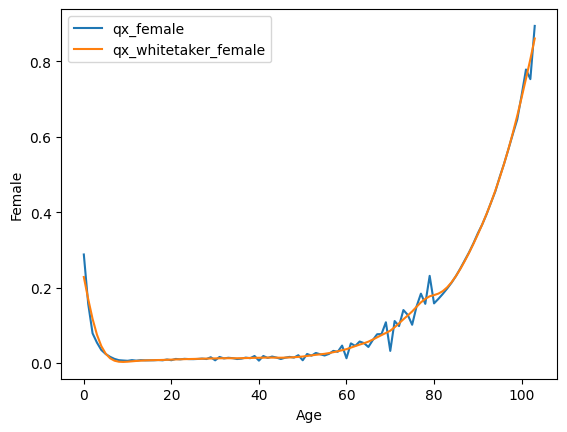

In [108]:
age = backup_bel_death["Age"].head(104)

sns.lineplot(x = age, y = qx_1841_female, label = "qx_female")
sns.lineplot(x = age, y = smoothed_qx_female, label = "qx_whitetaker_female")
plt.legend()

LAMBDA


In [109]:
dx_female = backup_bel_death["Female"]
L_female = backup_bel_population["Female"]
smoothed_double_female = np.tile(smoothed_qx_female, 150)
selisih_smoothed = len(smoothed_double_female) - len(L_female)
t = backup_bel_death["Year"]
t0 = 1872

numerator = np.log(dx_female / (L_female * smoothed_double_female)) * (t - t0)

index = 104
data = []

for _ in range(104):
    hasil = 0
    for z in range(len(numerator)):
        if z == index:
            hasil += numerator[z]
    data.append(hasil)
    index += 1

numerator = pd.Series(data)
denominator = np.sum((t - t0) ** 2)
lambda_female = - numerator / denominator
lambda_female

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


0     -6.571703e-11
1      3.371536e-09
2      6.972609e-10
3      3.323055e-09
4      2.398799e-09
           ...     
99     1.503081e-09
100    1.717129e-09
101    1.223568e-09
102    6.284159e-10
103    2.578450e-09
Length: 104, dtype: float64

ALPHA


In [110]:
import numpy as np

tahun = np.arange(0, 150)

alpha = []

temp = 0

for i in range(150):
    for z in range(len(lambda_female)):
        logika1 = dx_female[temp] / (L_female[temp] * smoothed_double_female[temp])
        logika2 = np.exp(-lambda_female.values[z] * tahun[i])
        logika3 = np.exp(-lambda_female.values[z] * tahun[i]) ** 2
        hasil = logika1 * logika2
        alpha.append(hasil / logika3)
        temp += 1
        
alpha

/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_3900/1364360392.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  logika1 = dx_female[temp] / (L_female[temp] * smoothed_double_female[temp])


[1.2615177531017943,
 0.925263851668716,
 0.6722649393657115,
 0.7195445420242519,
 0.7706134954156332,
 0.9678899171387372,
 1.3047660325461694,
 1.7731782709628556,
 2.183411562400709,
 2.276543100391671,
 1.6757576529699767,
 1.6971090114959602,
 1.1442427762429557,
 1.2024710162431633,
 1.0321684205412476,
 0.9843321339984102,
 0.9578832344320434,
 1.011873790983211,
 0.874005346352518,
 1.0868390401264958,
 0.8233052682471403,
 1.142819276183505,
 0.983297687856689,
 1.0776079010217214,
 0.9898838161438952,
 0.9479170815565852,
 0.9726334650044242,
 1.0325653844801452,
 0.9016349232901911,
 1.274039455648728,
 0.5843481132949814,
 1.282060862597227,
 0.9608928534619168,
 1.0956820475522477,
 1.0193958384518407,
 0.8389760962395416,
 0.9043984947356337,
 1.0921363352950046,
 0.9445555189883416,
 1.3546079924634522,
 0.45257123879260286,
 1.308448363089985,
 0.9406541765811763,
 1.1914314399853256,
 1.019096108894956,
 0.7518506764683209,
 0.9927967832801827,
 1.102512627506905,
 0.

QX


In [111]:
qx_female = []

for i in range(150): #
    for z in range(len(smoothed_qx_female)):
        alpa = alpha[i]
        qxt0 = smoothed_qx_female[z]
        exponen = np.exp(-lambda_female.values[z] * tahun[i])
        hasil = alpa * qxt0 * exponen
        qx_female.append(hasil)

qx_female

[0.28792435122623106,
 0.21405896310267367,
 0.14772330791871374,
 0.09484732437214077,
 0.05651954043296035,
 0.031168439091721713,
 0.015926021356910954,
 0.007824206120825032,
 0.004380283310079968,
 0.0037164934673074314,
 0.004473444926713042,
 0.005766172431836622,
 0.007012007190654597,
 0.008030245487550686,
 0.008741326745330165,
 0.009228279583252952,
 0.009602252088062188,
 0.00995993360170745,
 0.01035757188612658,
 0.010863240920236744,
 0.011414514814712987,
 0.012043303021647973,
 0.012579826529806897,
 0.013026307909995977,
 0.013363958514080482,
 0.013675084135421435,
 0.014028471341242478,
 0.01442168286959406,
 0.014813890393337173,
 0.015211230350082717,
 0.015474122230950462,
 0.015879833255548575,
 0.01606244583344536,
 0.01610395032080515,
 0.016023521431495397,
 0.015994419773421007,
 0.016220984917798345,
 0.01665000804481384,
 0.017073205277152705,
 0.01743569980988828,
 0.017587953337514194,
 0.017998711405202046,
 0.018173904407350547,
 0.018174630045424765,

PIVOT TABEL


In [112]:
tabel = backup_bel_death
tabel["qx"] = qx_female
tabel.pivot(index='Age', columns='Year', values='qx')

Year,1872,1873,1874,1875,1876,1877,1878,1879,1880,1881,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
Age,,,,,,,,,,,,,,,,,,,,,
0,0.287924,0.211179,0.153435,0.164226,0.175882,0.220908,0.297795,0.404704,0.498334,0.519590,...,0.198319,0.210034,0.250721,0.221616,0.309027,0.112220,0.302813,0.229860,0.287754,0.253773
1,0.214059,0.157002,0.114072,0.122095,0.130761,0.164235,0.221397,0.300879,0.370489,0.386292,...,0.147441,0.156151,0.186400,0.164762,0.229748,0.083431,0.225128,0.170890,0.213932,0.188669
2,0.147723,0.108348,0.078722,0.084258,0.090239,0.113340,0.152788,0.207639,0.255677,0.266582,...,0.101750,0.107760,0.128635,0.113703,0.158550,0.057576,0.155362,0.117933,0.147636,0.130202
3,0.094847,0.069566,0.050544,0.054099,0.057939,0.072771,0.098099,0.133317,0.164160,0.171162,...,0.065330,0.069189,0.082592,0.073004,0.101799,0.036967,0.099752,0.075720,0.094791,0.083597
4,0.056520,0.041454,0.030119,0.032238,0.034526,0.043364,0.058457,0.079443,0.097823,0.101996,...,0.038930,0.041230,0.049216,0.043503,0.060662,0.022029,0.059442,0.045121,0.056486,0.049816
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,0.827086,0.606629,0.440756,0.471753,0.505236,0.634576,0.855441,1.162545,1.431505,1.492565,...,0.569687,0.603339,0.720215,0.636610,0.887706,0.322361,0.869855,0.660291,0.826598,0.728983
100,0.888056,0.651347,0.473246,0.506529,0.542480,0.681354,0.918501,1.248243,1.537030,1.602591,...,0.611682,0.647814,0.773306,0.683539,0.953144,0.346124,0.933977,0.708965,0.887531,0.782721
101,0.951407,0.697812,0.507006,0.542663,0.581178,0.729960,0.984024,1.337289,1.646677,1.716915,...,0.655317,0.694027,0.828472,0.732300,1.021139,0.370816,1.000604,0.759540,0.950845,0.838558


DEATH RATES

In [113]:
italy_death_rates = clean(pd.read_csv("/Applications/MAMP/htdocs/local/kodingakademi/Python/dyah_putri/Data pembanding/Italy/Italy , Death rates (period 1x1),.txt", delimiter = "\t"))
italy_death_rates[["Year", "Age"]] = italy_death_rates[["Year", "Age"]].astype(int)
italy_death_rates = italy_death_rates.drop([0]).reset_index(drop=True)
italy_death_rates

,Year,Age,Female,Male,Total
0,1872,0,0.262955,0.293463,0.278519
1,1872,1,0.136145,0.138152,0.137160
2,1872,2,0.093066,0.093273,0.093172
3,1872,3,0.053998,0.054161,0.054081
4,1872,4,0.035148,0.035531,0.035342
...,...,...,...,...,...
16645,2021,106,0.668888,0.401542,0.640907
16646,2021,107,0.727830,0.846666,0.741087
16647,2021,108,0.725006,1.034226,0.770157
16648,2021,109,0.831307,0.919283,0.842830


In [114]:
italy_2020 = italy_death_rates[16428:16532]
italy_2021 = italy_death_rates[16539:16642]

PERBANDINGAN TAHUN 2020

In [115]:
qx_female[15392:15496]

[0.2877543570761616,
 0.21393247117431974,
 0.1476360735527944,
 0.0947912777801452,
 0.05648614998380251,
 0.031150034058479003,
 0.015916622903104288,
 0.007819591770317432,
 0.0043777010595290435,
 0.0037143022369850124,
 0.004470807025768481,
 0.005762769931277523,
 0.00700786990514665,
 0.008025504126696448,
 0.008736166380639265,
 0.00922283037716336,
 0.009596581838817678,
 0.009954052068069888,
 0.010351456397888752,
 0.010856825134066357,
 0.011407776506042222,
 0.01203618944625699,
 0.012572400800399328,
 0.013018616244129914,
 0.01335606872942228,
 0.013667009094433398,
 0.014020186670048855,
 0.014413166242279474,
 0.014805143184553358,
 0.015202246222407711,
 0.015464989276905683,
 0.01587044650180644,
 0.016052966365680908,
 0.016094441508056206,
 0.016014062815663536,
 0.01598497728851925,
 0.016211404776704255,
 0.016640175742161773,
 0.017063126924966594,
 0.017425404729072412,
 0.017577575824331892,
 0.01798806824871769,
 0.01816318069091992,
 0.01816389950359599,
 0.

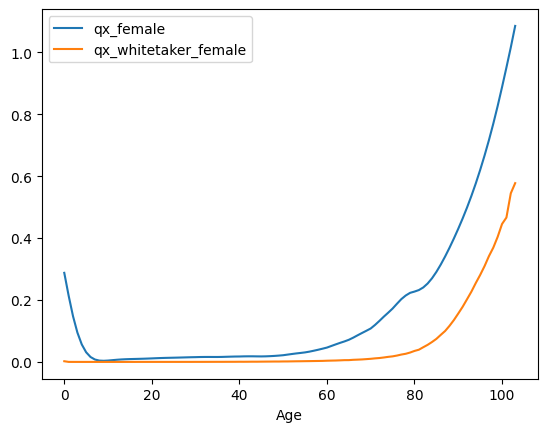

In [116]:
# Plot qx_female first
sns.lineplot(x=age, y=(qx_female[15392:15496]), label="qx_female", zorder=1)

# Plot qx_whitetaker_female on top with higher z-order
sns.lineplot(x=age, y=(italy_2020["Female"].values), label="qx_whitetaker_female", zorder=2)

plt.legend()
plt.show()
